# 05 การตรวจสอบความถูกต้องและการเปรียบเทียบวิธี

**ชุดการสอน:** Teach_SAR_flood_Mapping_ML | **เวลาโดยประมาณ:** 120 นาที | **ต้องทำก่อน:** `04`

## จุดประสงค์
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. สร้างและอ่าน confusion matrix และคำนวณ OA, precision, recall, F1, IoU, kappa
2. เปรียบเทียบแผนที่น้ำท่วมจาก threshold, Random Forest และ XGBoost ทั้งเชิงตัวเลขและเชิงพื้นที่
3. (ป.โท) ทดสอบความแตกต่างของสองโมเดลด้วย McNemar และประมาณพื้นที่พร้อมช่วงความเชื่อมั่น
4. วางแผน mini-project ของตนเอง

> **ย้ำอีกครั้ง:** ข้อมูลอ้างอิงใน notebook นี้คือ pseudo-label จากแผนที่ threshold ตัวเลขทั้งหมดจึงเป็น **ความสอดคล้องกับ threshold** ไม่ใช่ความถูกต้องเทียบกับน้ำท่วมจริง

## 0. เตรียมสภาพแวดล้อม
เซลล์นี้ดาวน์โหลดข้อมูลและฟังก์ชันกลาง (`sarflood_utils.py`) จาก GitHub ของรายวิชา **notebook นี้ไม่ต้องใช้ Google Earth Engine** เพราะข้อมูลถูกเตรียมไว้แล้วใน `00`

รูปทุกรูปใช้ป้ายกำกับภาษาอังกฤษ เพราะเป็นมาตรฐานของวารสารนานาชาติ และ Colab ไม่มีฟอนต์ไทยสำหรับ matplotlib

In [1]:
!pip -q install rasterio

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = 'Teach_SAR_flood_Mapping_ML'
if not os.path.isdir(REPO):
    !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git
sys.path.insert(0, REPO)
import sarflood_utils as su

DATA = f'{REPO}/data'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('ไฟล์ข้อมูล:', sorted(os.listdir(DATA)))

ไฟล์ข้อมูล: ['S1_20171017_VH.tif', 'S1_20171017_VV.tif', 'S1_20180109_VH.tif', 'S1_20180109_VV.tif', 'boundary_amphoe.geojson', 'boundary_province.geojson', 'dem_srtm.tif', 'ghsl_pop_2020.tif', 'jrc_seasonality.tif', 'readme.txt', 'slope_srtm.tif', 'worldcover_2020.tif']


## 1. สร้างข้อมูลและโมเดลซ้ำจาก `04`
ใช้ค่า seed เดิม จึงได้ตัวอย่างและการแบ่งชุดเหมือน `04` ทุกประการ

In [2]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

fm = su.flood_change_map(DATA, threshold=su.DIFF_THRESHOLD)
feats, grid = su.make_features(DATA)
amphoe, province = su.load_boundaries(DATA, grid['crs'])
FEATURES = su.FEATURE_SETS['sar_with_ratio']

df = su.sample_pseudo_labels(fm, feats, n_per_class=10000, margin=1.5, block_km=5.0, seed=42)
train, test = su.spatial_split(df, test_size=0.3, seed=42)
y_test = test['label'].to_numpy()

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                             tree_method='hist', n_jobs=-1, random_state=42),
}
pred = {}
for name, m in models.items():
    m.fit(train[FEATURES], train['label'])
    pred[name] = m.predict(test[FEATURES])
print('ฝึกโมเดลแล้ว:', list(models), '| ชุดทดสอบ', len(test), 'จุด')

ฝึกโมเดลแล้ว: ['Random Forest', 'XGBoost'] | ชุดทดสอบ 5375 จุด


## 2. Confusion matrix และตัวชี้วัด

| | ทำนาย: ท่วม | ทำนาย: ไม่ท่วม |
|---|---|---|
| **อ้างอิง: ท่วม** | TP | FN (ตรวจขาด, omission) |
| **อ้างอิง: ไม่ท่วม** | FP (ตรวจเกิน, commission) | TN |

$$OA = \frac{TP+TN}{N} \qquad Precision = \frac{TP}{TP+FP} \qquad Recall = \frac{TP}{TP+FN}$$

$$F1 = \frac{2\,Precision \cdot Recall}{Precision + Recall} \qquad IoU = \frac{TP}{TP+FP+FN} \qquad \kappa = \frac{p_o - p_e}{1 - p_e}$$

- **Precision** เทียบได้กับ user's accuracy ของคลาสน้ำท่วม: ในบริเวณที่แผนที่บอกว่าท่วม ท่วมจริงกี่ส่วน
- **Recall** เทียบได้กับ producer's accuracy: น้ำท่วมจริงถูกตรวจพบกี่ส่วน
- **IoU** เข้มงวดกว่า F1 และไม่นับ TN จึงเหมาะเมื่อคลาสน้ำท่วมมีสัดส่วนน้อย
- **Kappa** เทียบความสอดคล้อง $p_o$ กับที่คาดว่าจะเกิดโดยบังเอิญ $p_e$

In [3]:
from sklearn.metrics import confusion_matrix, cohen_kappa_score

def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision, recall = tp / (tp + fp), tp / (tp + fn)
    return {'OA': (tp + tn) / (tp + tn + fp + fn), 'Precision': precision, 'Recall': recall,
            'F1': 2 * precision * recall / (precision + recall), 'IoU': tp / (tp + fp + fn),
            'Kappa': cohen_kappa_score(y_true, y_pred)}

table = pd.DataFrame({name: metrics(y_test, p) for name, p in pred.items()}).T
table.round(3)

,OA,Precision,Recall,F1,IoU,Kappa
Random Forest,0.972,0.959,0.973,0.966,0.935,0.942
XGBoost,0.968,0.955,0.968,0.961,0.925,0.934


บันทึก: outputs/fig05_confusion_matrices.png


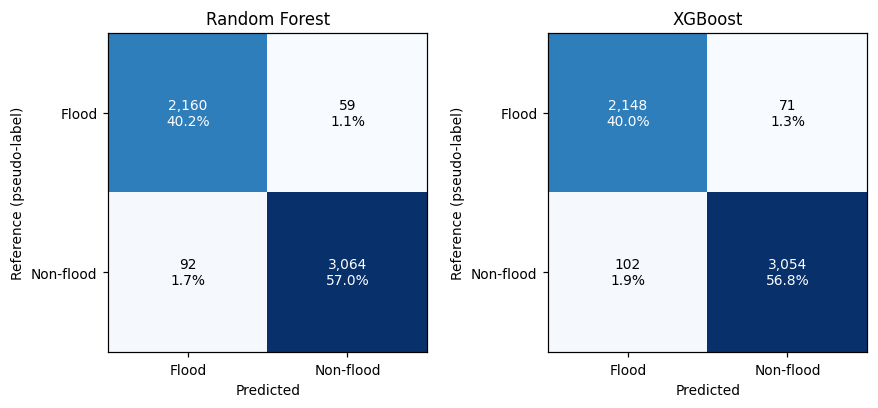

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), constrained_layout=True)
for ax, (name, p) in zip(axes, pred.items()):
    cm = confusion_matrix(y_test, p, labels=[1, 0])        # เรียงให้คลาสน้ำท่วมอยู่แถวและคอลัมน์แรก
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}\n{100 * v / cm.sum():.1f}%', ha='center', va='center',
                color='white' if v > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Flood', 'Non-flood']); ax.set_xlabel('Predicted')
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Flood', 'Non-flood']); ax.set_ylabel('Reference (pseudo-label)')
    ax.set_title(name)
su.save_fig(fig, 'fig05_confusion_matrices.png')
plt.show()

## 3. แผนที่ความน่าจะเป็นทั้งพื้นที่

ชุดทดสอบมีเฉพาะจุดที่ "มั่นใจ" แต่เมื่อทำนายทั้งภาพ โมเดลต้องตัดสินจุดกำกวมด้วย โมเดลให้ค่า **ความน่าจะเป็น** ของน้ำท่วม (0 ถึง 1) ซึ่งมีข้อมูลมากกว่าแผนที่สองคลาส เราตัดที่ 0.5 เพื่อให้ได้แผนที่น้ำท่วม แล้วตัดน้ำถาวรออกเช่นเดียวกับวิธี threshold

เซลล์นี้ทำนายทุกจุดภาพในพื้นที่ศึกษา กับข้อมูลจริงอาจใช้เวลาหลายนาที

บันทึก: outputs/fig05_probability_maps.png


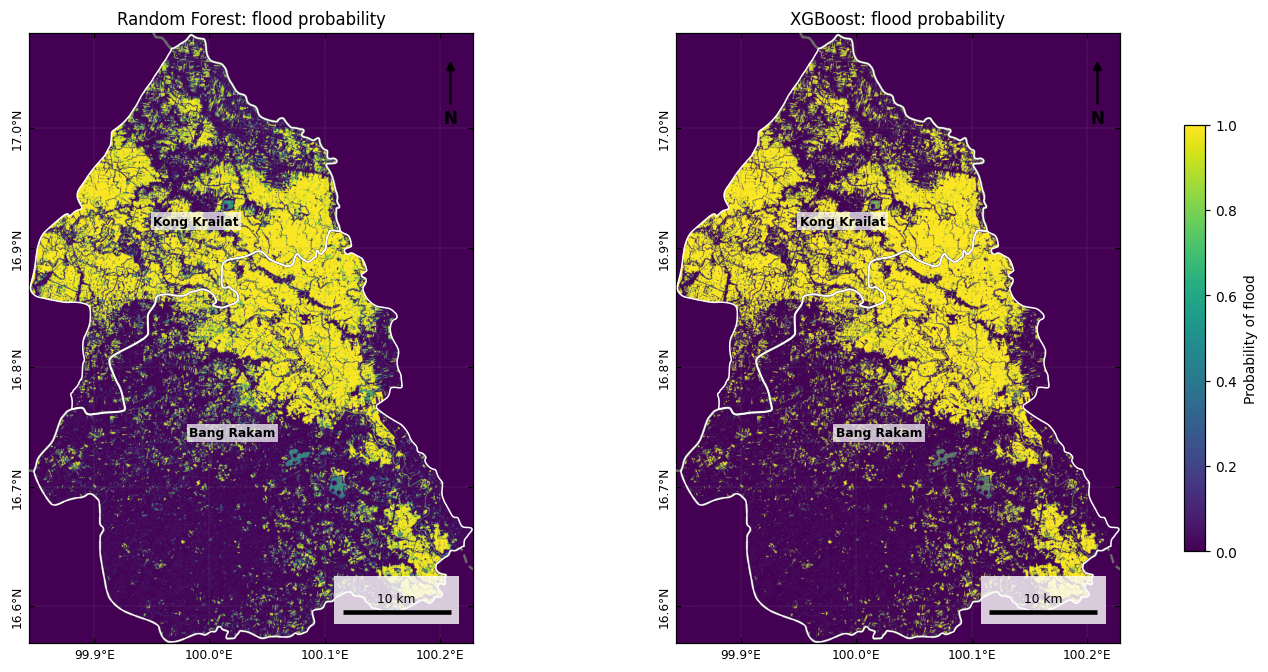

In [5]:
prob, ml_map = {}, {}
for name, m in models.items():
    prob[name] = su.predict_raster(m, feats, FEATURES, fm['valid'])
    ml_map[name] = (prob[name] >= 0.5) & ~fm['perm']

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, name in zip(axes, models):
    im = ax.imshow(prob[name], cmap='viridis', vmin=0, vmax=1, extent=su.extent(grid))
    su.journal_map(ax, grid, amphoe, province, edge='white')
    ax.set_title(f'{name}: flood probability')
fig.colorbar(im, ax=axes, shrink=0.7, label='Probability of flood')
su.save_fig(fig, 'fig05_probability_maps.png')
plt.show()

## 4. เปรียบเทียบพื้นที่และตำแหน่งที่เห็นต่าง
สองแผนที่อาจให้พื้นที่รวมใกล้กัน แต่ท่วมคนละตำแหน่ง จึงต้องดูทั้งตัวเลขและแผนที่

In [6]:
px_rai = su.pixel_area_m2(grid) / su.RAI_M2
maps = {'Threshold': fm['flood'], **ml_map}

area = pd.DataFrame({'flood_rai': {k: v.sum() * px_rai for k, v in maps.items()}})
area['diff_from_threshold_%'] = 100 * (area['flood_rai'] / area.loc['Threshold', 'flood_rai'] - 1)
area['agreement_with_threshold_%'] = [100 * (v == fm['flood'])[fm['valid']].mean() for v in maps.values()]
area.round(1)

,flood_rai,diff_from_threshold_%,agreement_with_threshold_%
Threshold,245971.1,0.0,100.0
Random Forest,305616.1,24.2,93.8
XGBoost,306936.4,24.8,93.7


In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

a, b = fm['flood'], ml_map['Random Forest']
cat = np.full(a.shape, np.nan)
cat[a & b] = 0; cat[a & ~b] = 1; cat[~a & b] = 2
colors = ['#1f4e9c', '#e69f00', '#d62728']
labels = ['Both flood', 'Threshold only', 'Random Forest only']

fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
ax.imshow(fm['flood_img'], cmap='gray', vmin=-27, vmax=-7, alpha=0.5, extent=su.extent(grid))
ax.imshow(np.ma.masked_invalid(cat), cmap=ListedColormap(colors), vmin=-0.5, vmax=2.5,
          extent=su.extent(grid), interpolation='nearest')
su.journal_map(ax, grid, amphoe, province)
su.add_inset(ax, amphoe, province)
ax.legend(handles=[Patch(color=c, label=f'{l} ({(cat == k).sum() * px_rai:,.0f} rai)')
                   for k, (c, l) in enumerate(zip(colors, labels))], loc='upper left', fontsize=7)
ax.set_title('Agreement between threshold and Random Forest flood maps')
su.save_fig(fig, 'fig05_agreement_map.png')
plt.show()

## 5. (ป.โท) สองโมเดลต่างกันอย่างมีนัยสำคัญหรือไม่: McNemar's test

ทั้งสองโมเดลถูกทดสอบบนจุดชุดเดียวกัน จึงต้องใช้การทดสอบแบบจับคู่ McNemar ดูเฉพาะจุดที่สองโมเดล **ตอบต่างกัน**

$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$$

โดย $b$ คือจำนวนจุดที่ RF ถูกแต่ XGBoost ผิด และ $c$ คือจำนวนที่กลับกัน สมมติฐานหลักคือสองโมเดลมีอัตราผิดพลาดเท่ากัน

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

ok_rf = pred['Random Forest'] == y_test
ok_xgb = pred['XGBoost'] == y_test
tab = pd.crosstab(pd.Series(ok_rf, name='RF correct'), pd.Series(ok_xgb, name='XGBoost correct'))
tab = tab.reindex(index=[True, False], columns=[True, False], fill_value=0)
res = mcnemar(tab.to_numpy(), exact=False, correction=True)
print(tab, '\n')
print(f'chi-square = {res.statistic:.2f}, p-value = {res.pvalue:.4f}')
print('ต่างกันอย่างมีนัยสำคัญที่ระดับ 0.05' if res.pvalue < 0.05 else 'ไม่พบความแตกต่างอย่างมีนัยสำคัญที่ระดับ 0.05')

## 6. (ป.โท) การประมาณพื้นที่พร้อมช่วงความเชื่อมั่น

การนับจุดภาพบนแผนที่ (pixel counting) ให้พื้นที่ที่มีอคติ เพราะแผนที่มีทั้งตรวจเกินและตรวจขาด Olofsson et al. (2014) เสนอให้ใช้ตัวอย่างอ้างอิงที่สุ่มแบบแบ่งชั้นตามคลาสของแผนที่ มาปรับแก้พื้นที่

ให้ $W_i$ เป็นสัดส่วนพื้นที่ของคลาสแผนที่ $i$ และ $n_{ij}$ เป็นจำนวนตัวอย่างที่แผนที่บอกคลาส $i$ แต่ข้อมูลอ้างอิงบอกคลาส $j$

$$\hat p_{ij} = W_i\frac{n_{ij}}{n_{i\cdot}} \qquad \hat A_j = A_{total}\sum_i \hat p_{ij} \qquad SE(\hat A_j) = A_{total}\sqrt{\sum_i W_i^2\,\frac{\frac{n_{ij}}{n_{i\cdot}}\left(1-\frac{n_{ij}}{n_{i\cdot}}\right)}{n_{i\cdot}-1}}$$

ช่วงความเชื่อมั่น 95% คือ $\hat A_j \pm 1.96\,SE$

ด้านล่างเป็นการ **สาธิตวิธีคำนวณ** โดยใช้แผนที่ Random Forest เป็นแผนที่ และใช้แผนที่ threshold แทนข้อมูลอ้างอิง ในงานจริงข้อมูลอ้างอิงต้องมาจากภาคสนามหรือการแปลด้วยสายตา

In [ ]:
rng = np.random.default_rng(42)
valid = fm['valid']
mapped, reference = ml_map['Random Forest'], fm['flood']
A_total = valid.sum() * px_rai
N_PER_STRATUM = 500

rows = []
for i, stratum in enumerate([valid & mapped, valid & ~mapped]):        # ชั้น: ท่วม, ไม่ท่วม ตามแผนที่
    idx = rng.choice(np.flatnonzero(stratum), size=N_PER_STRATUM, replace=False)
    n_flood = reference.ravel()[idx].sum()                             # ตัวอย่างที่ข้อมูลอ้างอิงบอกว่าท่วม
    rows.append({'map_class': ['flood', 'non-flood'][i], 'W': stratum.sum() / valid.sum(),
                 'n': N_PER_STRATUM, 'n_ref_flood': n_flood})
s = pd.DataFrame(rows)
p = s['n_ref_flood'] / s['n']
area_adj = A_total * (s['W'] * p).sum()
se = A_total * np.sqrt((s['W'] ** 2 * p * (1 - p) / (s['n'] - 1)).sum())

display(s.round(3))
print(f'พื้นที่จากการนับจุดภาพ (แผนที่ RF) : {mapped.sum() * px_rai:>12,.0f} ไร่')
print(f'พื้นที่ที่ปรับแก้แล้ว              : {area_adj:>12,.0f} ± {1.96 * se:,.0f} ไร่ (95% CI)')

## 7. แบบฝึกหัด

### ข้อ 1 คำนวณด้วยมือ
แผนที่หนึ่งมี TP = 420, FP = 60, FN = 80, TN = 440 จงคำนวณ OA, precision, recall, F1 และ IoU แล้วตรวจคำตอบด้วยโค้ด

<details><summary><b>เฉลย</b></summary>

- OA = (420 + 440) / 1000 = 0.860
- Precision = 420 / 480 = 0.875
- Recall = 420 / 500 = 0.840
- F1 = 2 × 0.875 × 0.840 / (0.875 + 0.840) = 0.857
- IoU = 420 / (420 + 60 + 80) = 0.750

```python
y_true = np.r_[np.ones(500), np.zeros(500)]
y_pred = np.r_[np.ones(420), np.zeros(80), np.ones(60), np.zeros(440)]
print({k: round(v, 3) for k, v in metrics(y_true, y_pred).items()})
```
IoU ต่ำกว่า F1 เสมอ (ยกเว้นเมื่อทั้งคู่เท่ากับ 0 หรือ 1) เพราะ IoU = F1 / (2 − F1)
</details>

### ข้อ 2 OA หลอกตาได้อย่างไร
สมมติพื้นที่ศึกษามีน้ำท่วมจริงเพียง 5% ถ้าโมเดลทำนายว่า "ไม่ท่วม" ทุกจุดภาพ OA, recall และ IoU ของคลาสน้ำท่วมจะเป็นเท่าไร

<details><summary><b>เฉลย</b></summary>

OA = 95% แต่ recall = 0 และ IoU = 0 โมเดลนี้ไม่มีประโยชน์เลยแม้ OA จะสูง เมื่อคลาสไม่สมดุลจึงต้องรายงานตัวชี้วัดของคลาสที่สนใจ (precision, recall, F1, IoU) ควบคู่กับ OA เสมอ ชุดทดสอบของเราสุ่มแบบสมดุล OA จึงยังตีความได้ แต่ไม่ได้สะท้อนสัดส่วนจริงของพื้นที่
</details>

### ข้อ 3 ปรับจุดตัดของความน่าจะเป็น
ถ้าหน่วยงานบรรเทาสาธารณภัยต้องการ **ไม่พลาด** พื้นที่น้ำท่วม ควรปรับจุดตัดจาก 0.5 ไปทางใด ลองคำนวณพื้นที่ที่จุดตัด 0.3, 0.5 และ 0.7

<details><summary><b>เฉลย</b></summary>

```python
for c in [0.3, 0.5, 0.7]:
    m = (prob['Random Forest'] >= c) & ~fm['perm']
    print(c, f'{m.sum() * px_rai:,.0f} ไร่')
```
ลดจุดตัดลง (เช่น 0.3) เพื่อเพิ่ม recall โดยยอมให้ precision ลดลง การเลือกจุดตัดเป็นการตัดสินใจเชิงนโยบาย ขึ้นกับว่าความผิดพลาดแบบใดมีต้นทุนสูงกว่า
</details>

### ข้อ 4 อ่านแผนที่ความเห็นต่าง
บริเวณ "Threshold only" และ "Random Forest only" กระจุกตัวที่ใด เช่น ตามขอบน้ำท่วม เขตชุมชน หรือริมแม่น้ำ เพราะอะไร

<details><summary><b>เฉลย</b></summary>

มักพบตามขอบของพื้นที่น้ำท่วม เพราะแผนที่ threshold มาจากภาพที่กรองแล้วจึงมีขอบเรียบ ส่วนโมเดลทำนายจากแบนด์ดิบทีละจุดภาพจึงมีขอบขรุขระและมีจุดกระจาย ในเขตชุมชนและพืชหนาแน่น VV กับ VH ให้ข้อมูลต่างกัน โมเดลที่ใช้หลายแบนด์จึงอาจตัดสินต่างจาก threshold ที่ใช้ VH เพียงแบนด์เดียว บริเวณเหล่านี้คือจุดที่ควรไปสำรวจภาคสนามก่อน
</details>

## 8. Mini-project

เลือกหนึ่งหัวข้อ ทำเป็นรายงาน 4–6 หน้า พร้อม notebook ที่รันซ้ำได้

| ระดับ | หัวข้อ |
|---|---|
| ป.ตรี | ทำซ้ำทั้งกระบวนการกับอำเภออื่นในลุ่มน้ำยม โดยแก้ `AMPHOES` ใน `00` แล้วเปรียบเทียบพื้นที่นาข้าวที่ถูกน้ำท่วม |
| ป.ตรี | เปรียบเทียบ VV กับ VH ในการตรวจจับน้ำท่วม ทั้งพื้นที่รวมและตำแหน่งที่เห็นต่าง |
| ป.ตรี/โท | ทำซ้ำกับเหตุการณ์น้ำท่วมปีอื่นของพื้นที่เดิม แล้ววิเคราะห์พื้นที่ท่วมซ้ำซาก |
| ป.โท | แปลจุดอ้างอิงด้วยสายตาอย่างน้อย 200 จุดจากภาพ Sentinel-2 หรือ Google Earth ช่วงเวลาใกล้เคียง แล้วประเมินความถูกต้องจริงของทั้งสามวิธีตามแนวทาง Olofsson et al. (2014) |
| ป.โท | เพิ่ม feature เชิงบริบท เช่น texture หรือระยะห่างจากแม่น้ำ แล้วทดสอบด้วย spatial cross-validation |

**สิ่งที่รายงานต้องมี:** คำถามวิจัย, ข้อมูลและวันที่ของภาพ, วิธีเลือก threshold พร้อมเหตุผล, ตารางพื้นที่เป็นไร่, แผนที่ที่มีองค์ประกอบครบ, ที่มาของข้อมูลอ้างอิง และข้อจำกัดของผลลัพธ์

## สรุปทั้งชุดการสอน
1. **00–01** ภาพ SAR วัด backscatter ผิวน้ำนิ่งมืด และต้องตรวจ orbit ก่อนเปรียบเทียบภาพ
2. **02** change detection ร่วมกับ threshold ที่หาเอง ให้แผนที่น้ำท่วมที่อธิบายได้ทุกขั้น
3. **03** แปลงแผนที่เป็นตัวเลขที่ใช้ตัดสินใจได้ ทั้งไร่ สิ่งปกคลุมดิน และประชากร
4. **04–05** machine learning ใช้หลายแบนด์พร้อมกันและให้ค่าความน่าจะเป็น แต่ดีได้เท่ากับคุณภาพของ label เท่านั้น

ข้อความที่สำคัญที่สุดคือ **แผนที่น้ำท่วมที่ไม่มีข้อมูลอ้างอิงอิสระยังไม่ใช่ผลงานวิจัยที่สมบูรณ์** ขั้นต่อไปของนิสิตคือการหาข้อมูลอ้างอิงจริง

## เอกสารอ้างอิง
- Olofsson, P. et al. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42–57.
- Foody, G. M. (2004). Thematic map comparison: evaluating the statistical significance of differences in classification accuracy. *Photogrammetric Engineering & Remote Sensing*, 70(5), 627–633.
- Notti, D. et al. (2018). Potential and limitations of open satellite data for flood mapping. *Remote Sensing*, 10, 1673.
- Canty, M. & Nielsen, A. (2017). Spatio-temporal analysis of change with Sentinel imagery on the Google Earth Engine. *ESA Conference on Big Data from Space*.